In [1]:
import sys
# Append the previous directory to the path
sys.path.append('../')

In [2]:
import numpy as np
import pandas as pd
from exp_utils import CounterPlotNice
from sklearn.ensemble import RandomForestClassifier

In [3]:
# Download wine dataset
! wget https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv

# Read wine dataset
wine = pd.read_csv('winequality-red.csv', sep=';')

X, y = wine.drop('quality', axis=1), wine['quality']

# Transform X to numpy
X  = X.to_numpy()
# Transform y to binary
y = np.where(y > 5, 1, 0)

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [4]:
# Make RF model for noisy dataset
model = RandomForestClassifier(random_state=42)

In [5]:
model.fit(X, y)

RandomForestClassifier(random_state=42)

In [6]:
sys.path.insert(0, "../../")

In [7]:
exp_nice = CounterPlotNice(
    predict_fn=model.predict_proba,
    X_train=X,
    y_train=y,
    cat_feat=[]
    )

Check if estimates are stable.

With outer edges ensured:

DEBUG:counterplots.utils.approx:Making 224 Shapley comparisons (max=448)
DEBUG:counterplots.utils.process:Sampled 126 unique coalitions
DEBUG:counterplots.utils.approx:Making 224 Shapley comparisons (max=448)
DEBUG:counterplots.utils.process:Sampled 127 unique coalitions
DEBUG:counterplots.utils.approx:Making 224 Shapley comparisons (max=448)
DEBUG:counterplots.utils.process:Sampled 127 unique coalitions
DEBUG:counterplots.utils.approx:Making 224 Shapley comparisons (max=448)
DEBUG:counterplots.utils.process:Sampled 128 unique coalitions
DEBUG:counterplots.utils.approx:Making 224 Shapley comparisons (max=448)
DEBUG:counterplots.utils.process:Sampled 128 unique coalitions
DEBUG:counterplots.utils.approx:Making 224 Shapley comparisons (max=448)
DEBUG:counterplots.utils.process:Sampled 128 unique coalitions
DEBUG:counterplots.utils.approx:Making 224 Shapley comparisons (max=448)
DEBUG:counterplots.utils.process:Sampled 126 unique coalitions
DEBUG:counterplots.utils.approx:Making 224 Shapl

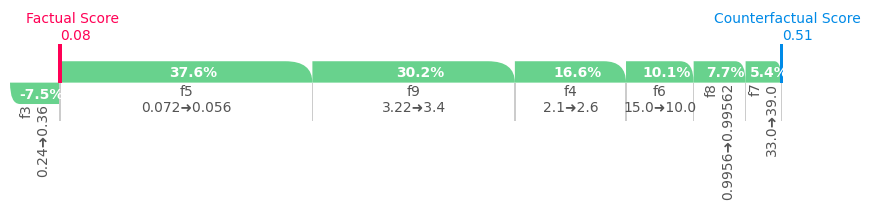

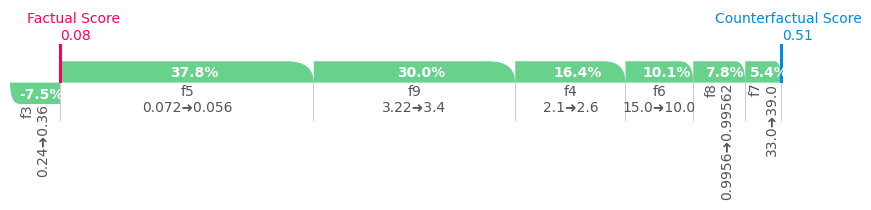

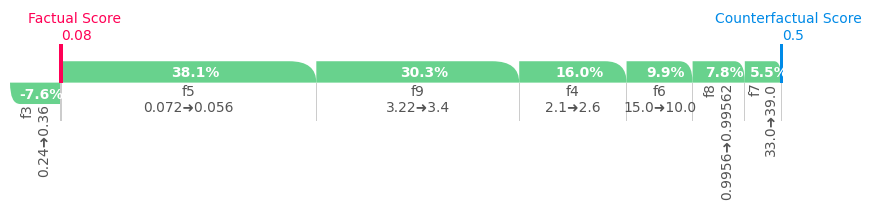

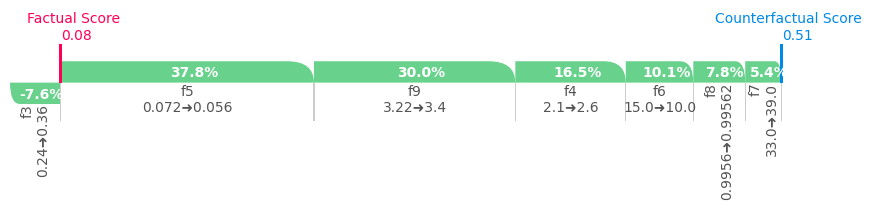

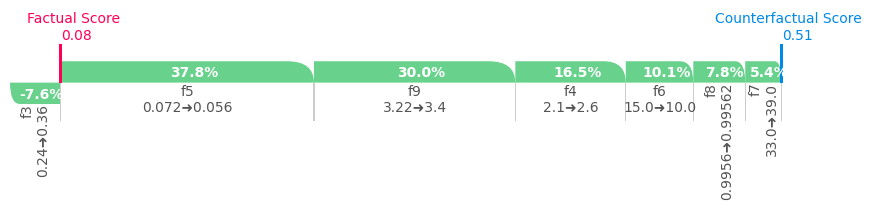

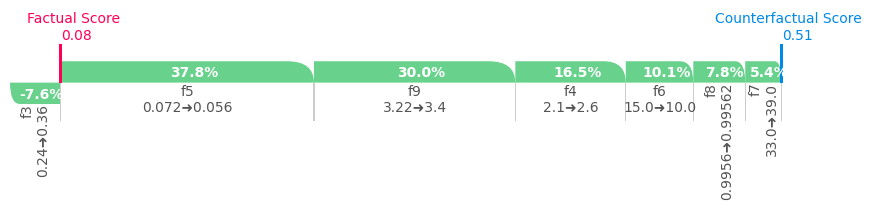

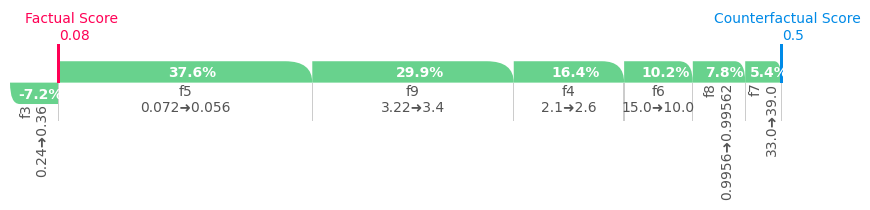

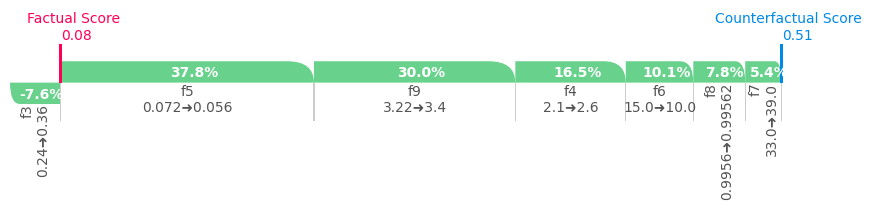

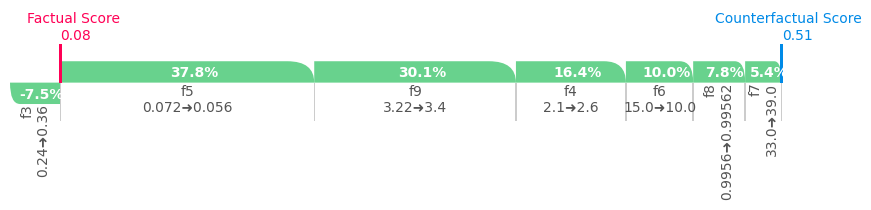

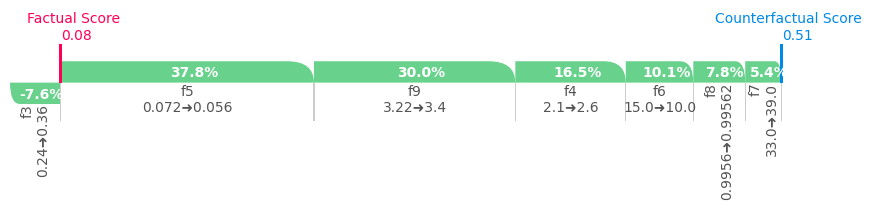

In [8]:
import matplotlib.pyplot as plt
import logging
logging.getLogger("counterplots.utils.approx").setLevel("DEBUG")
logging.getLogger("counterplots.utils.process").setLevel("DEBUG")

random_idx = 533  # large CFE, K = 7
n_instances, dim = X.shape
n_runs = 10

for _ in range(n_runs):
    x_cs = exp_nice.explain(
        np.array([X[random_idx]]),
        sample_kwargs={'n': .5, "ensure_outer_edges": True}
        )
    # countershapley_values = x_cs[0].countershapley_values()
    x_cs[0].countershapley()


# Calculate how much the Shapley value estimate deviates from real.

In [101]:
logging.getLogger("counterplots.utils.approx").setLevel("WARNING")
logging.getLogger("counterplots.utils.process").setLevel("WARNING")

N_instance_samples = 100
large_D_CFE_idx = 533  # CFE with D = 7
n_instances, dim = X.shape
max_sample_sizes_per_instance = 10

example_instance_idxs = np.random.choice(X.shape[0], N_instance_samples)
if large_D_CFE_idx not in example_instance_idxs: 
    example_instance_idxs = np.append(example_instance_idxs, large_D_CFE_idx)  # ensure the larger-dimensional CFE is in there

sample_sizes_by_dim = {}
estimate_deviations = {}

for example_instance_idx in example_instance_idxs:

    x_instance = X[example_instance_idx:example_instance_idx+1]

    x_cs = exp_nice.explain(x_instance)
    real_cs = x_cs[0].countershapley_values()

    real_vals = np.asarray(real_cs['feature_values'])
    n_feats = real_vals.size
    cf_dim = len(x_cs[0].idx_feat_diff)

    if cf_dim not in sample_sizes_by_dim:
        sample_sizes_by_dim[cf_dim] = np.linspace(
            1 / cf_dim,
            1,
            min(max_sample_sizes_per_instance, cf_dim)
        )

    sample_sizes = sample_sizes_by_dim[cf_dim]
    deviations = []

    for sample_size in sample_sizes:
        x_cs = exp_nice.explain(
            x_instance,
            sample_kwargs={'n': sample_size, 'ensure_outer_edges': True}
        )

        est_vals = np.asarray(
            x_cs[0].countershapley_values()['feature_values']
        )

        deviation = np.mean(np.abs((est_vals - real_vals) / real_vals))
        deviations.append(deviation)

    estimate_deviations.setdefault(cf_dim, []).append(deviations)

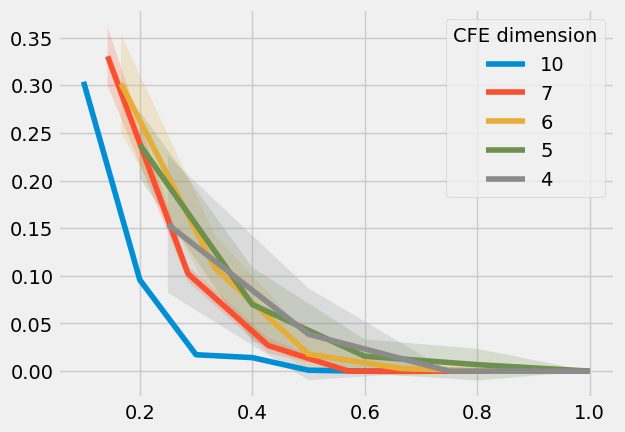

In [105]:
plt.style.use("fivethirtyeight")

# Sort per dimension
estimate_deviations = {k: v for k, v in reversed(sorted(estimate_deviations.items()))}

fig, ax = plt.subplots()

for dim, ys in estimate_deviations.items():
    x = sample_sizes_by_dim[dim]
    if dim < 4: continue
    m, s = np.mean(ys, axis=0), np.std(ys, axis=0)
    plt.plot(x, m, label=dim)
    plt.fill_between(x, m-s, m+s, alpha=.2)
plt.legend(title="CFE dimension")
plt.show()

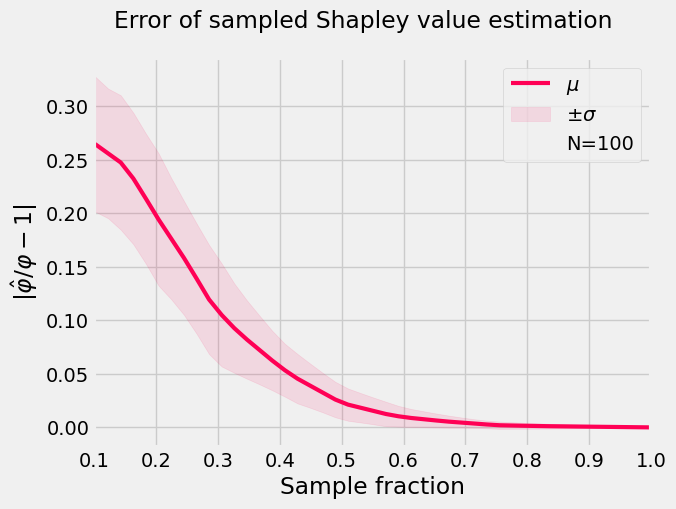

In [145]:
# Common x-grid
x_common = np.linspace(0, 1, 50)

all_means = []

fig, ax = plt.subplots()

for dim, ys in estimate_deviations.items():
    if dim < 4: continue
    x = sample_sizes_by_dim[dim]
    ys = np.asarray(ys)
    m = ys.mean(axis=0)
    # interpolate onto common grid
    m_interp = np.interp(x_common, x, m)
    all_means.append(m_interp)

# aggregate across dimensions
all_means = np.vstack(all_means)
mean_over_dims = all_means.mean(axis=0)
std_over_dims = all_means.std(axis=0)

ax.plot(
    x_common, 
    mean_over_dims, 
    lw=3,  
    c="#ff0055",
    label="$\mu$"
    )
ax.fill_between(
    x_common,
    mean_over_dims - std_over_dims,
    mean_over_dims + std_over_dims,
    alpha=0.1,
    color="#ff0055",
    label="$\pm \sigma$"
)
plt.plot([], [], ' ', label="N={}".format(N_instance_samples))
ax.set_xlim((.1, 1))

ax.set_xlabel("Sample fraction")
fig.suptitle("Error of sampled Shapley value estimation")
ax.set_ylabel("$|\hat{\\varphi}/\\varphi - 1|$")
plt.legend()
fig.savefig("../_static/approx_shapley_accuracy.svg", bbox_inches="tight")
plt.show()

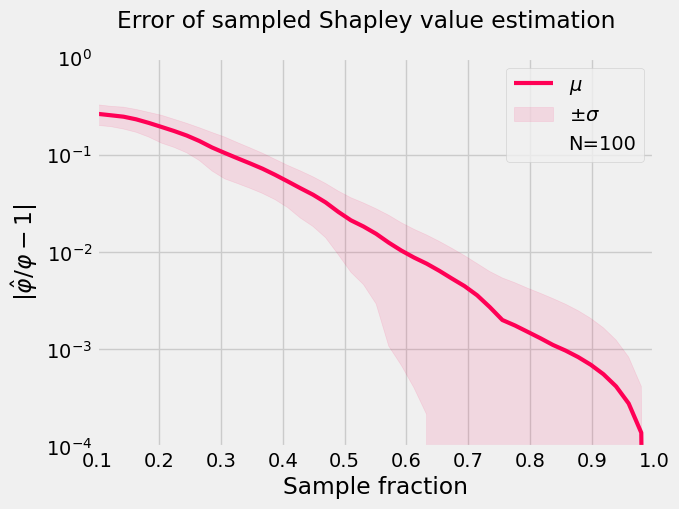

In [146]:
fig, ax = plt.subplots()
ax.plot(
    x_common, 
    mean_over_dims, 
    lw=3,  
    c="#ff0055",
    label="$\mu$"
    )
ax.fill_between(
    x_common,
    mean_over_dims - std_over_dims,
    mean_over_dims + std_over_dims,
    alpha=0.1,
    color="#ff0055",
    label="$\pm \sigma$"
)
plt.plot([], [], ' ', label="N={}".format(N_instance_samples))
ax.set_xlim((.1, 1))

ax.set_xlabel("Sample fraction")
fig.suptitle("Error of sampled Shapley value estimation")
ax.set_ylabel("$|\hat{\\varphi}/\\varphi - 1|$")

plt.yscale('log')
plt.ylim((1e-4, 1))
plt.legend()
fig.savefig("../_static/approx_shapley_accuracy_log.svg", bbox_inches="tight")
plt.show()